In [1]:
# ==============================================================================
# CELL 0: IMPORTS & CONFIGURATION
# ==============================================================================
import os
import glob
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

def matplotlib_default_config():
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm",
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "legend.fontsize": 12,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
    }
    return font, rcnew

%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [3]:
# ==============================================================================
# CELL 1: LOAD ALL SIMULATIONS (TNG50-2, 3, 4) — 5 RUNS EACH
# ==============================================================================
# Data source: the production halo-centered campaign (637 halos, 5 mass bins,
# 30 log-spaced impact parameters + b=0, 363 skewers/halo), run at 3 levels of
# the TNG50 resolution ladder with the "peak_plus_blend" HCD-isolation pipeline
# (Sec. 2.3 of the paper). 5 independent realizations per resolution level.
HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

# Impact parameters are logarithmically spaced (e.g. 0.01, 0.0134, 0.018, ...),
# so matching on 'r_mult_round' requires enough decimals to keep adjacent grid
# points distinct -- rounding to 2 decimals (as before) collapses several of
# the finely-spaced inner bins onto each other.
R_MULT_DECIMALS = 4

# This notebook lives in notebooks_TNG/, but the data_* directories live one
# level up, at the repo root -- so resolve them relative to REPO_DIR rather
# than to whatever the Jupyter process's current working directory happens to
# be (Jupyter normally sets it to the notebook's own directory, which is why
# plain relative paths silently found nothing).
REPO_DIR = os.path.abspath('..')
DEFINITIVES_DIR = os.path.join(REPO_DIR, 'definitives')
os.makedirs(DEFINITIVES_DIR, exist_ok=True)

# --- Simulation definitions ---
SIM_CONFIGS = {
     'TNG50-2': {
         'data_dir': os.path.join(REPO_DIR, 'data_TNG50-2_snap025_5runs_peak_plus_blend_sfneutral'),
         'pattern': 'TNG50-2_z3_637Halos_HCDMode_Stratified_run*.pkl',
         'color': 'tab:blue',
         'ls': '-',
         'label': 'TNG50-2 (High Res)',
    },
    'TNG50-3': {
        'data_dir': os.path.join(REPO_DIR, 'data_TNG50-3_snap025_5runs_peak_plus_blend_sfneutral'),
        'pattern': 'TNG50-3_z3_637Halos_HCDMode_Stratified_run*.pkl',
        'color': 'tab:orange',
        'ls': '--',
        'label': 'TNG50-3',
    },
    'TNG50-4': {
        'data_dir': os.path.join(REPO_DIR, 'data_TNG50-4_snap025_5runs_peak_plus_blend_sfneutral'),
        'pattern': 'TNG50-4_z3_637Halos_HCDMode_Stratified_run*.pkl',
        'color': 'tab:green',
        'ls': ':',
        'label': 'TNG50-4',
    },
}

# --- Load runs for each simulation ---
sim_data = {}  # key: sim_name -> list of DataFrames (one per run)

for sim_name, cfg in SIM_CONFIGS.items():
    data_dir = cfg['data_dir']
    pattern  = os.path.join(data_dir, cfg['pattern'])
    files    = sorted(glob.glob(pattern))

    if len(files) == 0:
        print(f"  [!] WARNING: No files found for {sim_name} in {data_dir}. Skipping.")
        continue

    runs = []
    for rf in files:
        df = pd.read_pickle(rf)
        df.attrs = {}  # avoid a pandas repr bug triggered by non-empty .attrs
        df['r_mult_round']  = df['r_multiplier'].round(R_MULT_DECIMALS)
        df['halo_mass_msun'] = df['halo_mass'] * MASS_CONVERSION_FACTOR
        runs.append(df)

    sim_data[sim_name] = runs
    print(f"{sim_name}: {len(runs)} runs loaded "
          f"({[len(r) for r in runs]} rows each)")

# --- Determine common impact parameters (union across sims) ---
all_radii_sets = []
for sim_name, runs in sim_data.items():
    for df_run in runs:
        all_radii_sets.append(set(df_run['r_mult_round'].unique()))

# Use the radii from the first simulation's first run as reference
ref_sim   = list(sim_data.keys())[0]
ref_radii = np.sort(sim_data[ref_sim][0]['r_mult_round'].unique())
print(f"\nReference impact parameters from {ref_sim} ({len(ref_radii)}):")
print(f"  {ref_radii}")

n_sims = len(sim_data)
print(f"\n{n_sims} simulations loaded successfully.")

TNG50-2: 5 runs loaded ([231231, 231231, 231231, 231231, 231231] rows each)
TNG50-3: 5 runs loaded ([231231, 231231, 231231, 231231, 231231] rows each)
TNG50-4: 5 runs loaded ([231231, 231231, 231231, 231231, 231231] rows each)

Reference impact parameters from TNG50-2 (31):
  [0.00000e+00 1.00000e-02 1.34000e-02 1.80000e-02 2.41000e-02 3.24000e-02
 4.34000e-02 5.83000e-02 7.81000e-02 1.04800e-01 1.40600e-01 1.88600e-01
 2.53000e-01 3.39300e-01 4.55200e-01 6.10500e-01 8.19000e-01 1.09850e+00
 1.47350e+00 1.97660e+00 2.65130e+00 3.55640e+00 4.77050e+00 6.39900e+00
 8.58350e+00 1.15137e+01 1.54443e+01 2.07166e+01 2.77887e+01 3.72751e+01
 5.00000e+01]

3 simulations loaded successfully.


saved /home/vroberto/FakeSpectra_DLAs/definitives/app_covering_resolution.pdf


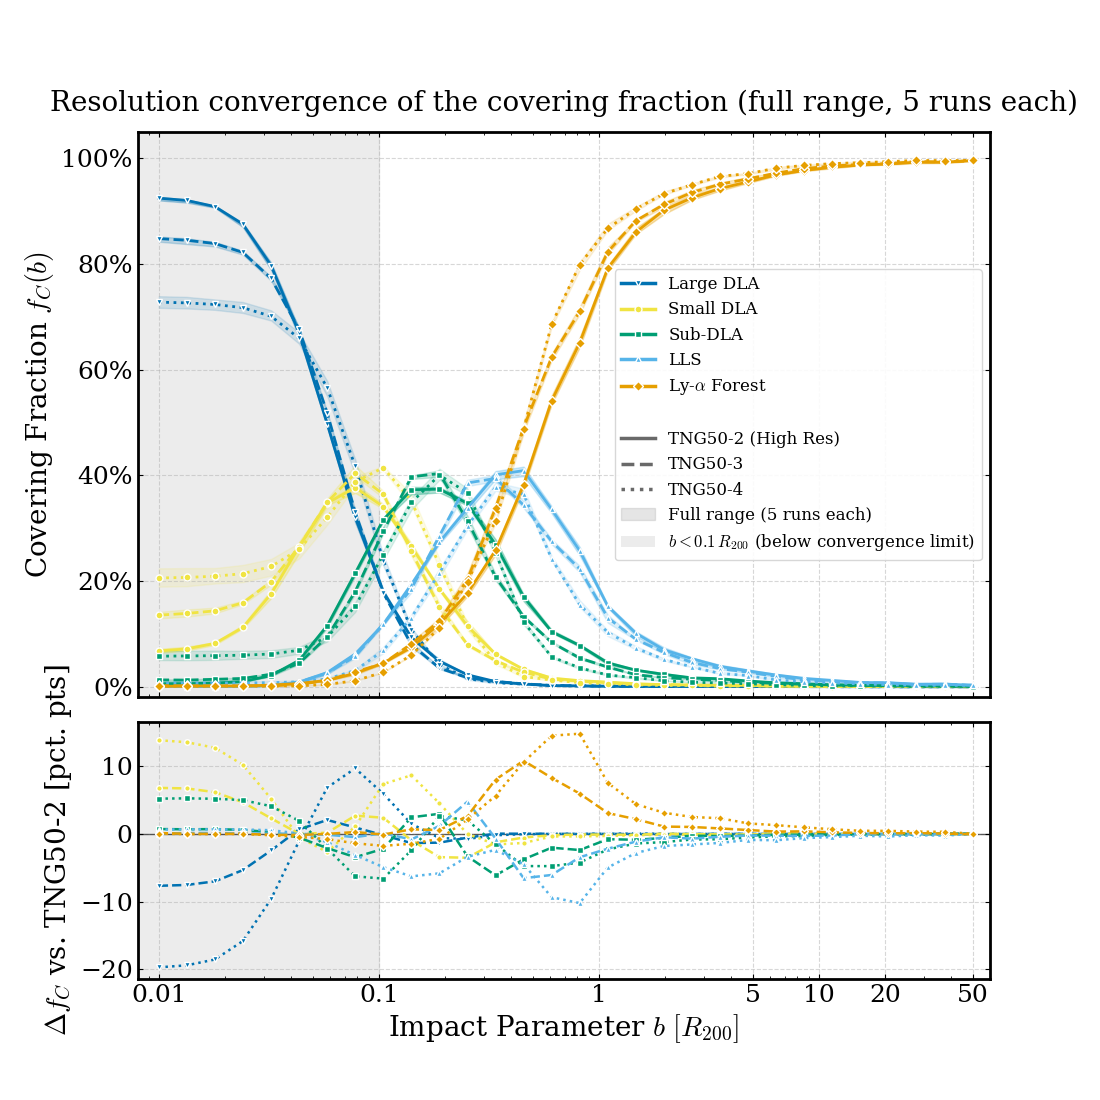

In [4]:
# ==============================================================================
# CELL 2: FIGURE app:covering_resolution -- COVERING-FRACTION CONVERGENCE
#          ACROSS THE RESOLUTION LADDER (Appendix A.1 of the paper)
# ==============================================================================
# Top panel : differential covering fraction f_C(b), all 3 resolutions overlaid
#             (one line per absorber class x resolution level), as in the
#             main-text Fig. hcds_percent_vs_b but for TNG50-4/3/2.
# Bottom panel: the "ratio to TNG50-2" the appendix caption asks for, shown as
#             the signed difference Delta f_C = f_C(sim) - f_C(TNG50-2), in
#             percentage points -- this stays well-defined even where f_C -> 0
#             (a true ratio blows up/is undefined there), while still reading
#             off directly as "how many percentage points does this resolution
#             miss the production run by".
#
# With only 5 realizations, a quoted +-Nsigma is itself very noisy (see Sec.
# "Error estimation" of the paper). As in 10_variance.ipynb, we shade
# the FULL RANGE spanned by the 5 realizations instead of +-Nsigma.

# Absorber-class colours -- SAME mapping used throughout the project (see
# 10_variance.ipynb's cat_styles/ridgeline and 14_Temperatures.ipynb's
# CLASS_COLORS): forest E69F00, LLS 56B4E9, Sub-DLA 009E73, Small-DLA F0E442,
# Large-DLA 0072B2.
CLASS_COLORS = {
    'Forest':    '#E69F00',
    'LLS':       '#56B4E9',
    'Sub_DLA':   '#009E73',
    'Small_DLA': '#F0E442',
    'Large_DLA': '#0072B2',
}

cat_styles = {
    'Large_DLA': {'color': CLASS_COLORS['Large_DLA'], 'marker': 'v',
                  'label': r'Large DLA'},
    'Small_DLA': {'color': CLASS_COLORS['Small_DLA'], 'marker': 'o',
                  'label': r'Small DLA'},
    'Sub_DLA':   {'color': CLASS_COLORS['Sub_DLA'],   'marker': 's',
                  'label': r'Sub-DLA'},
    'LLS':       {'color': CLASS_COLORS['LLS'],       'marker': '^',
                  'label': r'LLS'},
    'Forest':    {'color': CLASS_COLORS['Forest'],    'marker': 'D',
                  'label': r'Ly-$\alpha$ Forest'},
}

# Convergence limit adopted in the main text (Sec. 3 / Sec. 2.1): b >~ 0.1 R200.
B_CONVERGENCE_LIMIT = 0.1

# --- Compute fractions per run per simulation ---
def compute_fractions_per_run(runs, radii):
    fracs = {cat: [] for cat in cat_styles}
    for df_run in runs:
        run_fracs = {cat: [] for cat in cat_styles}
        for b_val in radii:
            df_b = df_run[df_run['r_mult_round'] == b_val]
            tot  = len(df_b)
            if tot > 0:
                nhi = df_b['log_n_hi']
                run_fracs['Large_DLA'].append(len(nhi[nhi >= 21.0]) / tot)
                run_fracs['Small_DLA'].append(len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot)
                run_fracs['Sub_DLA'].append(len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot)
                run_fracs['LLS'].append(len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot)
                run_fracs['Forest'].append(len(nhi[nhi < 17.2]) / tot)
            else:
                for cat in cat_styles:
                    run_fracs[cat].append(0.0)
        for cat in cat_styles:
            fracs[cat].append(run_fracs[cat])
    for cat in cat_styles:
        fracs[cat] = np.array(fracs[cat])
    return fracs

sim_fractions = {}
for sim_name, runs in sim_data.items():
    radii = np.sort(runs[0]['r_mult_round'].unique())
    sim_fractions[sim_name] = {
        'radii': radii,
        'fracs': compute_fractions_per_run(runs, radii),
    }

# --- Alpha Mapping for full-range shading per simulation ---
alpha_map = {
    'TNG50-2': 0.30,  # Darkest shade
    'TNG50-3': 0.20,  # Intermediate shade
    'TNG50-4': 0.13,  # Lightest shade
}

# --- PLOT ---
fig_cov, (ax_main, ax_ratio) = plt.subplots(
    2, 1, figsize=(11, 11), sharex=True,
    gridspec_kw={'height_ratios': [2.2, 1.0], 'hspace': 0.06},
)

# ---- Top panel: absolute covering fraction ----
for cat, cstyle in cat_styles.items():
    for sim_name, cfg in SIM_CONFIGS.items():
        if sim_name not in sim_fractions:
            continue

        radii = sim_fractions[sim_name]['radii']
        data  = sim_fractions[sim_name]['fracs'][cat]  # (n_runs, n_radii)

        mean_f = np.mean(data, axis=0)
        min_f  = np.min(data, axis=0)
        max_f  = np.max(data, axis=0)

        ls = cfg['ls']
        shade_alpha = alpha_map.get(sim_name, 0.07)

        # Only positive radii for log scale
        mask   = radii > 0
        r_plot = radii[mask]
        m_plot = mean_f[mask]
        lo_plot = min_f[mask]
        hi_plot = max_f[mask]

        ax_main.fill_between(
            r_plot, lo_plot, hi_plot,
            color=cstyle['color'], alpha=shade_alpha, zorder=1,
        )
        ax_main.plot(
            r_plot, m_plot,
            color=cstyle['color'], lw=2.0, ls=ls,
            marker=cstyle['marker'], ms=5, mec='white', zorder=3,
        )

# ---- Bottom panel: Delta f_C relative to TNG50-2, per class ----
ref_sim_name = 'TNG50-2'
if ref_sim_name in sim_fractions:
    radii_ref = sim_fractions[ref_sim_name]['radii']
    mask_ref  = radii_ref > 0
    r_ref     = radii_ref[mask_ref]

    for cat, cstyle in cat_styles.items():
        mean_ref = np.mean(sim_fractions[ref_sim_name]['fracs'][cat], axis=0)[mask_ref]

        for sim_name, cfg in SIM_CONFIGS.items():
            if sim_name == ref_sim_name or sim_name not in sim_fractions:
                continue
            mean_sim = np.mean(sim_fractions[sim_name]['fracs'][cat], axis=0)[mask_ref]
            delta_pct = (mean_sim - mean_ref) * 100.0

            ax_ratio.plot(
                r_ref, delta_pct,
                color=cstyle['color'], lw=1.8, ls=cfg['ls'],
                marker=cstyle['marker'], ms=4, mec='white', zorder=3,
            )

    ax_ratio.axhline(0.0, color='black', lw=1.0, alpha=0.6, zorder=2)

ax_ratio.axvspan(0.008, B_CONVERGENCE_LIMIT, color='gray', alpha=0.15, zorder=0)
ax_main.axvspan(0.008, B_CONVERGENCE_LIMIT, color='gray', alpha=0.15, zorder=0)

# ---- Aesthetics: top panel ----
ax_main.grid(True, ls='--', alpha=0.5)
ax_main.set_xscale('log')
ax_main.set_ylim(-0.02, 1.05)
ax_main.set_xlim(0.008, 60)
ax_main.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))
ax_main.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_main.set_title(
    r'Resolution convergence of the covering fraction (full range, 5 runs each)',
    pad=15,
)

# ---- Aesthetics: bottom (ratio/difference) panel ----
ax_ratio.grid(True, ls='--', alpha=0.5)
ax_ratio.set_xscale('log')
ax_ratio.set_xlim(0.008, 60)
ax_ratio.set_xticks([0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0])
ax_ratio.set_xticklabels(['0.01', '0.1', '1', '5', '10', '20', '50'])
ax_ratio.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_ratio.set_ylabel(r'$\Delta f_C$ vs. TNG50-2 [pct. pts]')

# ---- Composite legend (top panel) ----
legend_cat = [
    Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'],
           ms=5, mec='white', label=c['label'])
    for c in cat_styles.values()
]
legend_cat.append(Line2D([0], [0], color='none', label=' '))

legend_sim = [
    Line2D([0], [0], color='dimgray', lw=2.5, ls=cfg['ls'],
           label=cfg['label'])
    for sim_name, cfg in SIM_CONFIGS.items()
    if sim_name in sim_data
]
legend_sim.append(
    patches.Patch(facecolor='gray', alpha=0.20, edgecolor='gray',
                  label='Full range (5 runs each)')
)
legend_sim.append(
    patches.Patch(facecolor='gray', alpha=0.15, edgecolor='none',
                  label=rf'$b < {B_CONVERGENCE_LIMIT}\,R_{{200}}$ (below convergence limit)')
)

ax_main.legend(
    handles=legend_cat + legend_sim, loc='center right',
    frameon=True, fontsize=12, edgecolor='lightgray',
    facecolor='white', framealpha=0.9,
)

out_fig = os.path.join(DEFINITIVES_DIR, "app_covering_resolution.pdf")
fig_cov.savefig(out_fig, bbox_inches='tight')
print(f"saved {out_fig}")

plt.show()

In [6]:
# ==============================================================================
# CELL 2b: PER-CLASS CONVERGENCE RADIUS (quantitative counterpart to Fig. 2)
# ==============================================================================
# For each absorber class, report the TNG50-3->TNG50-2 and TNG50-4->TNG50-3
# fractional differences as a function of b, and the smallest impact parameter
# beyond which BOTH steps stay under a chosen tolerance for the rest of the
# sampled range -- i.e. the class-by-class convergence radius the appendix
# text (Sec. "Convergence of the covering fraction") asks for.

TOLERANCE_PCT_PTS = 2.0  # matches the "<2% at larger impact parameters" claim

def stepwise_diff(simA, simB, cat):
    fA = np.mean(sim_fractions[simA]['fracs'][cat], axis=0)
    fB = np.mean(sim_fractions[simB]['fracs'][cat], axis=0)
    return np.abs(fA - fB) * 100.0  # percentage points, defined on ref_radii

def convergence_radius(diffs, radii, tol):
    """Smallest b such that diffs stays <= tol for every larger b in-sample."""
    ok = diffs <= tol
    for i in range(len(radii)):
        if np.all(ok[i:]):
            return radii[i]
    return np.nan

print("=" * 100)
print(f"  PER-CLASS RESOLUTION CONVERGENCE OF f_C(b)  (tolerance = {TOLERANCE_PCT_PTS} pct. pts)")
print("=" * 100)
print(f"{'Class':<12} | {'max |Δ| 3→2':>12} | {'max |Δ| 4→3':>12} | "
      f"{'b_conv (3→2)':>14} | {'b_conv (4→3)':>14}")
print("-" * 100)

for cat in cat_styles:
    d32 = stepwise_diff('TNG50-2', 'TNG50-3', cat)
    d43 = stepwise_diff('TNG50-3', 'TNG50-4', cat)

    b32 = convergence_radius(d32, ref_radii, TOLERANCE_PCT_PTS)
    b43 = convergence_radius(d43, ref_radii, TOLERANCE_PCT_PTS)

    print(f"{cat:<12} | {d32.max():>11.2f}% | {d43.max():>11.2f}% | "
          f"{b32:>12.3f} R200 | {b43:>12.3f} R200")

print("-" * 100)
print("b_conv is the smallest impact parameter beyond which the step stays "
      f"below {TOLERANCE_PCT_PTS} pct. pts for every larger b in the sampled grid.")
print("=" * 100)

  PER-CLASS RESOLUTION CONVERGENCE OF f_C(b)  (tolerance = 2.0 pct. pts)
Class        |  max |Δ| 3→2 |  max |Δ| 4→3 |   b_conv (3→2) |   b_conv (4→3)
----------------------------------------------------------------------------------------------------
Large_DLA    |        7.67% |       12.28% |        0.078 R200 |        0.189 R200
Small_DLA    |        7.00% |        9.58% |        0.339 R200 |        0.339 R200
Sub_DLA      |        6.12% |        5.32% |        1.099 R200 |        0.819 R200
LLS          |        6.53% |        8.13% |        1.474 R200 |        1.474 R200
Forest       |       10.79% |        8.84% |        1.977 R200 |        2.651 R200
----------------------------------------------------------------------------------------------------
b_conv is the smallest impact parameter beyond which the step stays below 2.0 pct. pts for every larger b in the sampled grid.


Ridgeline impact parameters (13): [0.0583, 0.0781, 0.1048, 0.1406, 0.1886, 0.253, 0.3393, 0.4552, 0.6105, 0.819, 1.0985, 1.4735, 1.9766]
saved /home/vroberto/FakeSpectra_DLAs/definitives/Fig_A3_1.pdf


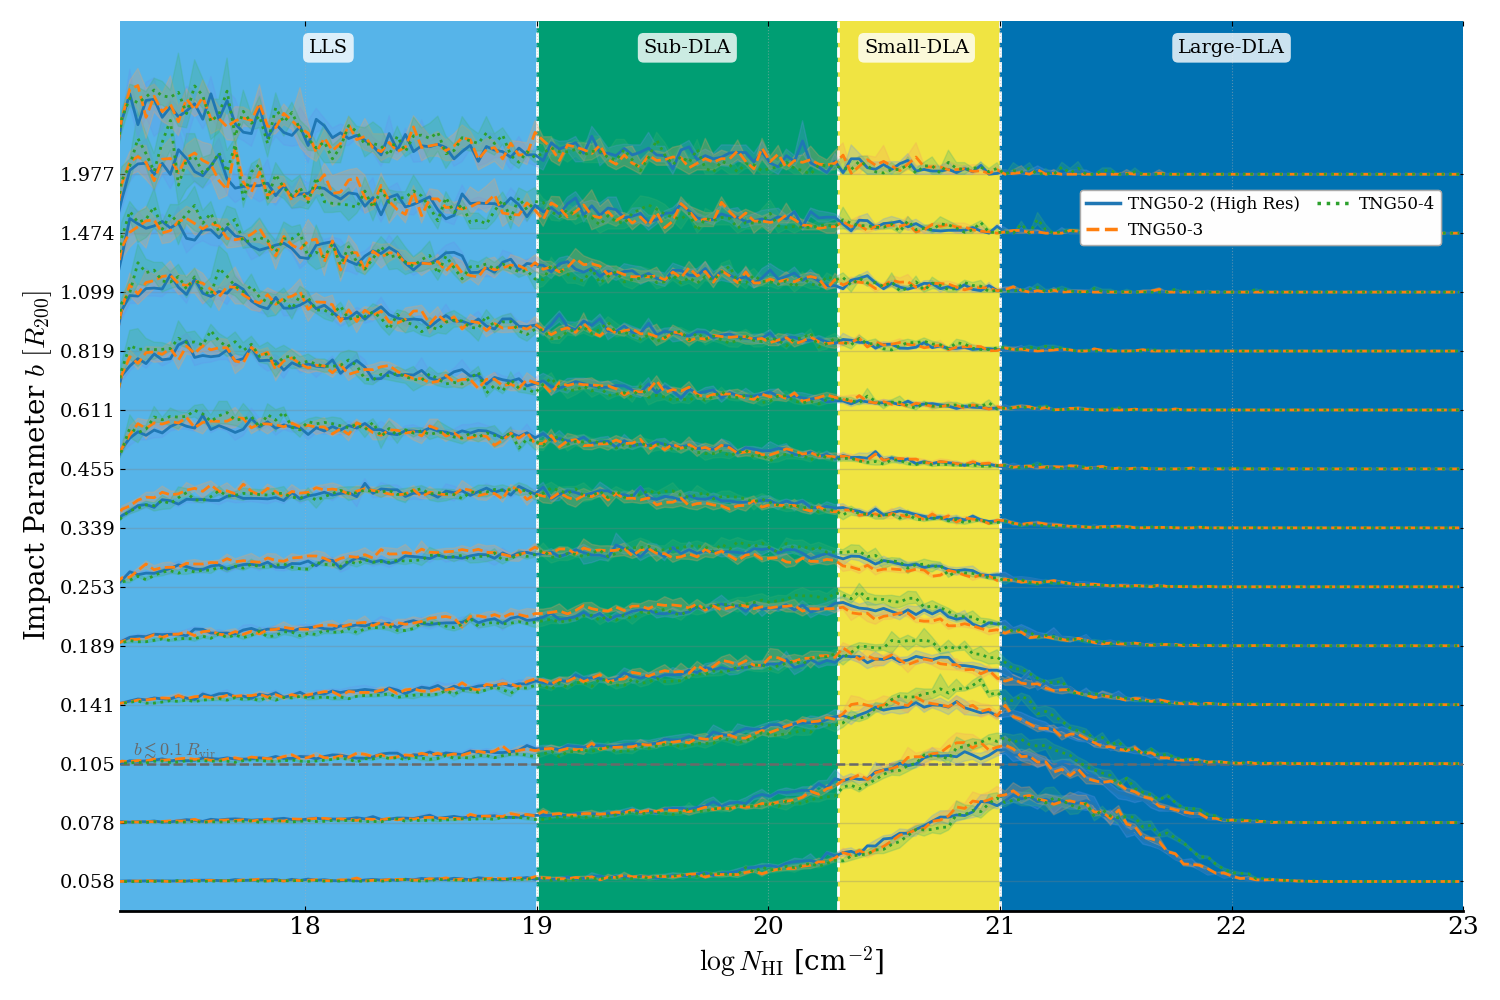

In [7]:
# ==============================================================================
# CELL 3: FIGURE app:nhi_resolution -- RIDGELINE, ALL SIMULATIONS,
#          ALL MASSES COMBINED (DENSITY-NORMALIZED)   [Appendix A.2]
# ==============================================================================

# Background colours -- CLASS_COLORS, defined once in CELL 2
c_forest   = CLASS_COLORS['Forest']
c_lls      = CLASS_COLORS['LLS']
c_subdla   = CLASS_COLORS['Sub_DLA']
c_smalldla = CLASS_COLORS['Small_DLA']
c_largedla = CLASS_COLORS['Large_DLA']

# ----------------------------------------------------------------------------
# overlap_factor: COSMETIC VERTICAL SCALING.
# Each ridgeline curve is drawn above an integer y-base. The natural scale of
# the probability density (per dex) is typically small (~0.5-2.0), so we
# multiply by overlap_factor to make curves visually prominent.
#
# This does NOT distort the relative areas/heights within or across curves:
# - The AREA under the curve between two N_HI limits equals the FRACTION of
#   skewers falling in that range.
# - A larger overlap_factor just stretches all heights uniformly.
#
# Typical good values: 2.0 - 4.0. Bigger = more overlap between rows.
# ----------------------------------------------------------------------------
overlap_factor = 1.8

# Histogram definitions (restricted to 16.0 -> 23.0)
num_bins  = 200
hist_bins = np.linspace(16.0, 23.0, num_bins + 1)
x_hist    = (hist_bins[:-1] + hist_bins[1:]) / 2
bin_width = hist_bins[1] - hist_bins[0]   # constant since we use linspace

# Sim-level colours and styles for ridgeline
SIM_RIDGE_STYLES = {
    'TNG50-2': {'color': 'tab:blue',   'fill': 'cornflowerblue', 'ls': '-'},
    'TNG50-3': {'color': 'tab:orange', 'fill': 'sandybrown',     'ls': '--'},
    'TNG50-4': {'color': 'tab:green',  'fill': 'mediumseagreen', 'ls': ':'},
}

# Resolution convergence limit: skewers at b < 0.1 R200 are not trusted
# (conservative, lowest-mass limit; see Appendix resolution tests). Same cut
# as 10_variance.ipynb's ridgeline.
B_RESOLUTION_LIMIT = 0.1

# --------------------------------------------------------------------------
# CORRECTED HISTOGRAM: density per dex (dn / d log N_HI / N_total)
# --------------------------------------------------------------------------
def density_hist(values, bins, tot_skewers):
    """
    Returns probability density per unit log N_HI, normalized to the curve's
    OWN total (tot_skewers = the number of HCD-bearing skewers at this (b,
    sim, mass bin), not all skewers including forest -- so every row's curve
    integrates to 1 over the full range regardless of how common an HCD is at
    that b. Matches the normalization used in 10_variance.ipynb's
    ridgeline (Cell 7): shape, not incidence, is what this plot shows.

    Height in each bin = (counts_in_bin / tot_skewers) / bin_width

    Properties:
    - Integral over the full range = 1 for any (b, sim, mass bin) that has at
      least one HCD-bearing skewer.
    - Integral over any sub-range [a, b] = fraction of THIS row's HCD
      population falling in that log N_HI interval.

    Parameters
    ----------
    values : 1D array of log N_HI values (already filtered to the valid range).
    bins   : histogram bin edges.
    tot_skewers : number of HCD-bearing skewers at this (b, sim, mass bin),
                  i.e. len(valid) BEFORE restricting to the histogram range.
    """
    if len(values) < 2 or tot_skewers == 0:
        return np.zeros(len(bins) - 1)

    counts, _ = np.histogram(values, bins=bins)
    bw = bins[1] - bins[0]

    return counts / (tot_skewers * bw)


def paint_ridgeline_multi(
    ax, sim_data, selected_b, mass_low=None, mass_high=None,
    title_text='', show_legend=True,
    b_resolution_limit=B_RESOLUTION_LIMIT
):
    """
    Ridgeline overlaid using DENSITY-PER-DEX-normalized histograms.

    Heights are proportional to (fraction of total skewers per dex of log N_HI),
    so visual areas correspond faithfully to category populations.

    With only 5 realizations per resolution level, the shaded band is the
    FULL RANGE (min-max) spanned by the 5 runs -- not a +-Nsigma band, which
    would be too noisy to trust with this few draws (same choice as in
    10_variance.ipynb).
    """

    # Background spans (x-axis starts at 17.2, so the Ly-alpha Forest span
    # is out of view and intentionally not drawn)
    ax.axvspan(17.2, 19.0, color=c_lls, zorder=0)
    ax.axvspan(19.0, 20.3, color=c_subdla, zorder=0)
    ax.axvspan(20.3, 21.0, color=c_smalldla, zorder=0)
    ax.axvspan(21.0, 23.0, color=c_largedla, zorder=0)

    # Threshold markers (17.2 dropped -- it now coincides with the left spine)
    for xv in [19.0, 20.3, 21.0]:
        ax.axvline(xv, color='white', ls='--', lw=2.0, zorder=0)

    # Regime Text Boxes at the top
    text_y_pos = 0.98
    bbox_props = dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        alpha=0.8,
        edgecolor="none"
    )

    ax.text(
        18.10, text_y_pos, 'LLS',
        transform=ax.get_xaxis_transform(),
        ha='center', va='top', fontsize=14,
        bbox=bbox_props, zorder=10
    )

    ax.text(
        19.65, text_y_pos, 'Sub-DLA',
        transform=ax.get_xaxis_transform(),
        ha='center', va='top', fontsize=14,
        bbox=bbox_props, zorder=10
    )

    ax.text(
        20.64, text_y_pos, 'Small-DLA',
        transform=ax.get_xaxis_transform(),
        ha='center', va='top', fontsize=14,
        bbox=bbox_props, zorder=10
    )

    ax.text(
        22.0, text_y_pos, 'Large-DLA',
        transform=ax.get_xaxis_transform(),
        ha='center', va='top', fontsize=14,
        bbox=bbox_props, zorder=10
    )

    ax.grid(axis='x', ls=':', alpha=0.5)
    ax.grid(axis='y', visible=False)

    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    # --- Resolution-limit boundary -----------------------------------------
    # Impact parameters below the convergence limit (b < 0.1 R200, the most
    # conservative/lowest-mass limit; see Appendix resolution tests) are not
    # trusted. Instead of shading that whole region, we mark only the
    # boundary between excluded and trusted rows with a dashed grey line
    # (drawn at the baseline of the first trusted row, i.e. above the last
    # excluded row's rising curve) plus a text annotation on top of it.
    if b_resolution_limit is not None:
        b_arr = np.asarray(selected_b, dtype=float)
        excluded = np.where(b_arr < b_resolution_limit)[0]

        if len(excluded) > 0:
            boundary_y = excluded.max() + 1.0

            ax.axhline(
                boundary_y,
                color='dimgray',
                ls='--',
                lw=1.8,
                zorder=2,
            )

            ax.text(
                0.01, boundary_y + 0.06,
                r'$b\lesssim0.1\,R_{\rm vir}$',
                transform=ax.get_yaxis_transform(),
                ha='left', va='bottom',
                fontsize=13,
                color='dimgray',
                zorder=10,
            )

    y_ticks  = []
    y_labels = []

    for i_b, b_val in enumerate(selected_b):

        # Match at the same precision used to build 'r_mult_round' in Cell 1
        # (rounding to only 2 decimals here would merge distinct, finely
        # log-spaced inner bins, e.g. 0.01 and 0.0134, onto the same b_round).
        b_round = np.round(b_val, R_MULT_DECIMALS)
        y_base  = i_b

        y_ticks.append(y_base)
        y_labels.append(f"{b_val:.3f}")

        ax.axhline(
            y_base,
            color='gray',
            lw=1.0,
            alpha=0.3,
            zorder=1
        )

        for sim_name, runs in sim_data.items():

            sty = SIM_RIDGE_STYLES.get(
                sim_name,
                {'color': 'black', 'fill': 'gray', 'ls': '-'}
            )

            hist_stack = []

            for df_run in runs:

                if mass_low is not None and mass_high is not None:
                    df_mass = df_run[
                        (df_run['halo_mass_msun'] >= mass_low) &
                        (df_run['halo_mass_msun'] < mass_high)
                    ]
                else:
                    df_mass = df_run

                df_b = df_mass[
                    df_mass['r_mult_round'] == b_round
                ]

                valid = df_b[
                    df_b['log_n_hi'] > 1.0
                ]['log_n_hi'].values

                n_hcd = len(valid)

                # Density per dex, normalized by the row's OWN total
                # (the number of HCD-bearing skewers here), not by all
                # skewers including forest -- same convention as
                # 10_variance.
                mask_hist = (
                    (valid >= 16.0) &
                    (valid <= 23.0)
                )

                hist_dens = density_hist(
                    valid[mask_hist],
                    hist_bins,
                    n_hcd
                )

                hist_stack.append(hist_dens)

            hist_stack = np.array(hist_stack)

            mean_hist = np.mean(hist_stack, axis=0)
            min_hist  = np.min(hist_stack, axis=0)
            max_hist  = np.max(hist_stack, axis=0)

            mean_scaled = mean_hist * overlap_factor
            lo_scaled   = min_hist * overlap_factor
            hi_scaled   = max_hist * overlap_factor

            # Full-range band (min-max across the 5 realizations) -- drawn
            # in the sim's lighter "fill" colour, distinct from the median
            # line's darker "color" (see the style legend added below).
            ax.fill_between(
                x_hist,
                y_base + lo_scaled,
                y_base + hi_scaled,
                color=sty['fill'],
                alpha=0.25,
                zorder=i_b + 3,
            )

            # Mean line
            ax.plot(
                x_hist,
                y_base + mean_scaled,
                color=sty['color'],
                lw=2.0,
                ls=sty['ls'],
                zorder=i_b + 5,
            )



    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=14)

    ax.set_xlim(17.2, 23.0)

    ax.set_ylim(
        -0.5,
        len(selected_b) - 1 + overlap_factor + 0.8
    )

    if title_text:
        ax.text(
            0.98, 0.90,
            title_text,
            transform=ax.transAxes,
            fontsize=18,
            ha='right',
            va='top',
            fontweight='bold',
            bbox=dict(
                facecolor='white',
                alpha=0.9,
                edgecolor='none'
            ),
            zorder=30,
        )

    if show_legend:

        # Legend 1: simulation identity (colour + linestyle per sim)
        sim_lines = []

        for sim_name in sim_data.keys():

            sty = SIM_RIDGE_STYLES.get(
                sim_name,
                {'color': 'black', 'fill': 'gray', 'ls': '-'}
            )

            lbl = SIM_CONFIGS.get(
                sim_name, {}
            ).get('label', sim_name)

            sim_lines.append(
                Line2D(
                    [0], [0],
                    color=sty['color'],
                    lw=2.5,
                    ls=sty['ls'],
                    label=lbl
                )
            )

        leg_sims = ax.legend(
            handles=sim_lines,
            loc='upper right',
            ncol=2,
            frameon=True,
            fontsize=12,
            bbox_to_anchor=(0.99, 0.82),
            facecolor='white',
            framealpha=0.95,
            edgecolor='darkgray',
            columnspacing=1.0,
            handletextpad=0.5,
        )

        leg_sims.set_zorder(100)
        ax.add_artist(leg_sims)

        # Legend 2 (separate): what the median line vs. the shaded band
        # mean, per ridgeline -- drawn with each sim's own colour pair so
        # it reads as one legend per simulation rather than a single
        # generic grey swatch.
        style_handles = []

        for sim_name in sim_data.keys():

            sty = SIM_RIDGE_STYLES.get(
                sim_name,
                {'color': 'black', 'fill': 'gray', 'ls': '-'}
            )

            lbl = SIM_CONFIGS.get(
                sim_name, {}
            ).get('label', sim_name)

            style_handles.append(
                Line2D(
                    [0], [0],
                    color=sty['color'],
                    lw=2.0,
                    ls=sty['ls'],
                    label=f'{lbl} median'
                )
            )
            style_handles.append(
                patches.Patch(
                    facecolor=sty['fill'],
                    alpha=0.25,
                    edgecolor='none',
                    label=f'{lbl} min-max range'
                )
            )


# --- Filter impact parameters: 0.05 to 2.0 R200 (same cut as
# 10_variance.ipynb's ridgeline: shrinks the shaded sub-floor region
# relative to the earlier b >= 0.0 version) ---
SELECTED_B = sorted([
    b for b in ref_radii
    if 0.05 <= b <= 2.0
])

n_sel = len(SELECTED_B)

print(
    f"Ridgeline impact parameters ({n_sel}): {SELECTED_B}"
)

# --- Plot: All Masses Combined ---
fig_height = max(10, 0.70 * n_sel)

fig_ridge_all, ax_ridge_all = plt.subplots(
    figsize=(15, fig_height)
)

paint_ridgeline_multi(
    ax_ridge_all,
    sim_data,
    SELECTED_B,
    mass_low=None,
    mass_high=None,
    title_text='',
    show_legend=True,
)

ax_ridge_all.set_xlabel(
    r"$\log N_{\rm HI}$ [cm$^{-2}$]",
    fontsize=20
)

ax_ridge_all.set_ylabel(
    r'Impact Parameter $b \ [R_{200}]$',
    fontsize=20
)

plt.tight_layout()

out_fig = os.path.join(DEFINITIVES_DIR, "Fig_A3_1.pdf")
fig_ridge_all.savefig(out_fig, bbox_inches='tight')
print(f"saved {out_fig}")

plt.show()

In [ ]:
# ==============================================================================
# CELL 3b: QUANTITATIVE COUNTERPART TO FIG. app:nhi_resolution
# ==============================================================================
# The caption of Fig. app:nhi_resolution asks three questions: are the median
# log N_HI, the width of the distribution, and the high-column tail stable
# with resolution, and is the radial migration of Sec. 3.1.2 preserved?
# Answer each with numbers, at the same three representative impact
# parameters quoted in the main text (b=0, b~0.26 R200, b~1 R200).

def nhi_summary_stats(runs, b_round):
    """Median, 16-84 width, and 99th-percentile log N_HI at a fixed b,
    pooling all 5 realizations (HCD-classified skewers only, log_n_hi > 1)."""
    vals = []
    for df_run in runs:
        df_b = df_run[df_run['r_mult_round'] == b_round]
        vals.append(df_b[df_b['log_n_hi'] > 1.0]['log_n_hi'].values)
    vals = np.concatenate(vals) if vals else np.array([])
    if len(vals) < 5:
        return np.nan, np.nan, np.nan, len(vals)
    p16, p50, p84, p99 = np.percentile(vals, [16, 50, 84, 99])
    return p50, p84 - p16, p99, len(vals)

# Nearest available radii to the three main-text reference points
targets = [0.0, 0.26, 1.0]
b_refs = [ref_radii[np.argmin(np.abs(ref_radii - t))] for t in targets]

print("=" * 100)
print("  RESOLUTION STABILITY OF THE SKEWER-LEVEL log N_HI DISTRIBUTION")
print("=" * 100)
print(f"{'b [R200]':>10} | {'Sim':<10} | {'median':>8} | {'16-84 width':>12} | "
      f"{'p99':>7} | {'N (5 runs)':>10}")
print("-" * 100)

for b_ref in b_refs:
    for sim_name, runs in sim_data.items():
        med, width, p99, n = nhi_summary_stats(runs, b_ref)
        print(f"{b_ref:>10.4f} | {sim_name:<10} | {med:>8.3f} | {width:>12.3f} | "
              f"{p99:>7.3f} | {n:>10d}")
    print("-" * 100)

print("Read across a fixed b: stable median/width/p99 across TNG50-2/3/4 "
      "confirms the ridgeline shapes -- and the radial migration between the "
      "three b values -- are numerically converged, not resolution artifacts.")
print("=" * 100)

In [ ]:
# ==============================================================================
# OPTIONAL: SANITY-CHECK — verify visual areas match covering-fraction percentages
# ==============================================================================
print("\n" + "="*90)
print("SANITY CHECK: Integrating ridgeline density vs. raw category counts")
print("="*90)

check_b = 0.01  # change to inspect other impact parameters
print(f"\nAt b = {check_b} R200:\n")

for sim_name, runs in sim_data.items():
    sim_counts = {'Large_DLA': 0, 'Small_DLA': 0, 'Sub_DLA': 0, 'LLS': 0, 'Forest': 0}
    sim_total = 0
    for df_run in runs:
        df_b = df_run[df_run['r_mult_round'] == np.round(check_b, R_MULT_DECIMALS)]
        nhi = df_b['log_n_hi'].values
        sim_total += len(nhi)
        sim_counts['Large_DLA'] += np.sum(nhi >= 21.0)
        sim_counts['Small_DLA'] += np.sum((nhi >= 20.3) & (nhi < 21.0))
        sim_counts['Sub_DLA']   += np.sum((nhi >= 19.0) & (nhi < 20.3))
        sim_counts['LLS']       += np.sum((nhi >= 17.2) & (nhi < 19.0))
        sim_counts['Forest']    += np.sum(nhi < 17.2)
    
    if sim_total == 0:
        continue
    print(f"--- {sim_name}  (total = {sim_total} sightlines) ---")
    for cat, n in sim_counts.items():
        print(f"  {cat:<10s}: {n:5d}  ({100*n/sim_total:5.1f}%)")
    print()

print("Check: the ridgeline is normalized to each row's OWN HCD-bearing total")
print("       (matching 10_variance.ipynb), not to sim_total above, so the")
print("       purple area equals Large-DLA % divided by (1 - Forest %), not the raw")
print("       Large-DLA % from this table.")
print("="*90)

In [ ]:
# ==============================================================================
# CELL 5: SUMMARY TABLES
# ==============================================================================

# Read redshift from data
z_ref = list(sim_data.values())[0][0].iloc[0]['redshift'] \
        if 'redshift' in list(sim_data.values())[0][0].columns else 3.0
a_ref = 1.0 / (1.0 + z_ref)

# ══════════════════════════════════════════════════════════════════════════
# TABLE 1: ABSORBER FRACTIONS AT MAXIMUM IMPACT PARAMETER
# ══════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 110)
print(f"  TABLE 1 — ABSORBER FRACTIONS AT MAXIMUM IMPACT PARAMETER  (mean ± 1σ, 5 runs)")
print("=" * 110)

header = (f"{'Simulation':<22} | {'b_max':>6} | {'L-DLA':>12} | {'S-DLA':>12} "
          f"| {'Sub-DLA':>12} | {'LLS':>12} | {'Forest':>12}")
print(header)
print("-" * 110)

for sim_name, runs in sim_data.items():
    radii = np.sort(runs[0]['r_mult_round'].unique())
    max_b = radii[radii > 0].max()

    pcts_all = []
    for df_run in runs:
        df_b = df_run[df_run['r_mult_round'] == np.round(max_b, R_MULT_DECIMALS)]
        tot  = len(df_b)
        if tot > 0:
            nhi = df_b['log_n_hi']
            pcts_all.append([
                len(nhi[nhi >= 21.0]) / tot * 100,
                len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot * 100,
                len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot * 100,
                len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot * 100,
                len(nhi[nhi < 17.2]) / tot * 100,
            ])

    arr   = np.array(pcts_all)
    means = np.mean(arr, axis=0)
    stds  = np.std(arr, axis=0)

    lbl = SIM_CONFIGS[sim_name]['label']
    row = f"{lbl:<22} | {max_b:>5.1f} "
    for m, s in zip(means, stds):
        row += f"| {m:>5.1f}±{s:>4.1f}% "
    print(row)

print("=" * 110)


# ══════════════════════════════════════════════════════════════════════════
# TABLE 2: LARGEST HALO R200 IN EACH SIMULATION
# ══════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 105)
print(f"  TABLE 2 — LARGEST HALO R200 IN EACH SIMULATION  (run 0, z = {z_ref:.2f})")
print("=" * 105)
print(f"{'Simulation':<22} | {'Halo ID':>10} | {'M200 [M☉]':>16} | "
      f"{'R200 [ckpc/h]':>14} | {'R200 [pkpc]':>12} | {'R200 [pMpc]':>12}")
print("-" * 105)

for sim_name, runs in sim_data.items():
    df0 = runs[0].drop_duplicates(subset=['halo_id']).copy()
    idx_max = df0['halo_mass_msun'].idxmax()
    row_max = df0.loc[idx_max]

    halo_id   = int(row_max['halo_id'])
    mass_msun = row_max['halo_mass_msun']
    r200_ckpch = row_max['halo_r200']  # already in comoving kpc/h

    r200_pkpc = r200_ckpch / HUBBLE_H * a_ref
    r200_pmpc = r200_pkpc / 1e3

    lbl = SIM_CONFIGS[sim_name]['label']
    print(f"{lbl:<22} | {halo_id:>10d} | {mass_msun:>16.4e} | "
          f"{r200_ckpch:>14.2f} | {r200_pkpc:>12.2f} | {r200_pmpc:>12.6f}")

print("=" * 105 + "\n")


# ══════════════════════════════════════════════════════════════════════════
# TABLE 3: FOREST FRACTION AT ALL IMPACT PARAMETERS
# ══════════════════════════════════════════════════════════════════════════
print("\n" + "=" * 100)
print(f"  TABLE 3 — FOREST FRACTION (log NHI < 17.2) AT SELECTED IMPACT PARAMETERS")
print("=" * 100)

header = f"{'b [R200]':>10}"
for sim_name in sim_data.keys():
    lbl = SIM_CONFIGS[sim_name]['label'].split(' ')[0]
    header += f" | {lbl:>12}"
print(header)
print("-" * 100)

for b_val in SELECTED_B:
    b_round = np.round(b_val, R_MULT_DECIMALS)
    row = f"{b_val:>10.4f}"

    for sim_name, runs in sim_data.items():
        pcts = []
        for df_run in runs:
            df_b = df_run[df_run['r_mult_round'] == b_round]
            tot  = len(df_b)
            if tot > 0:
                p = len(df_b[df_b['log_n_hi'] < 17.2]) / tot * 100
            else:
                p = np.nan
            pcts.append(p)

        arr = np.array(pcts)
        row += f" | {np.nanmean(arr):>6.1f}±{np.nanstd(arr):>4.1f}%"
        
    print(row)

print("=" * 100 + "\n")

In [ ]:
# ==============================================================================
# CELL 6: RESOLUTION-LADDER CONVERGENCE OF THE COVERING FRACTION
#          (fills in the "~X%" / "~Y%" numbers quoted in Sec. 2.1)
# ==============================================================================
# Reuses sim_fractions computed in Cell 2 (no need to reload the pickles again
# now that Cell 1 already points at the "peak_plus_blend" production runs).

OUTER_MASK = ref_radii >= B_CONVERGENCE_LIMIT
INNER_MASK = (ref_radii > 0) & (ref_radii < B_CONVERGENCE_LIMIT)

def agg_diff_summary(simA, simB, mask, label):
    diffs, per_cat = [], {}
    for cat in cat_styles:
        fA = np.mean(sim_fractions[simA]['fracs'][cat], axis=0)
        fB = np.mean(sim_fractions[simB]['fracs'][cat], axis=0)
        d = np.abs(fA - fB)[mask] * 100
        per_cat[cat] = d
        diffs.append(d)
    diffs = np.concatenate(diffs)
    print(f"--- {label} ---")
    print(f"    mean |Δf_C| = {diffs.mean():.2f} pct pts   "
          f"median = {np.median(diffs):.2f}   max = {diffs.max():.2f}")
    for cat, d in per_cat.items():
        print(f"      {cat:<10s} mean={d.mean():5.2f}  max={d.max():5.2f}")
    return diffs.mean()

print("\n=== Covering-fraction convergence, outside the core (b >= 0.1 R200) ===")
X_diff = agg_diff_summary('TNG50-2', 'TNG50-3', OUTER_MASK,
                           'TNG50-3 -> TNG50-2  (this is "X" in the Sec. 2.1 paragraph)')
Y_diff = agg_diff_summary('TNG50-3', 'TNG50-4', OUTER_MASK,
                           'TNG50-4 -> TNG50-3  (this is "Y" in the Sec. 2.1 paragraph)')

print("\n=== Covering-fraction differences in the core (b < 0.1 R200), for reference ===")
_ = agg_diff_summary('TNG50-2', 'TNG50-3', INNER_MASK, 'TNG50-3 -> TNG50-2, inner')
_ = agg_diff_summary('TNG50-2', 'TNG50-4', INNER_MASK, 'TNG50-4 -> TNG50-2, inner')

print(f"\n>>> Sec. 2.1 sentence: 'changes our observables by ~{X_diff:.1f} per cent "
      f"outside the innermost impact parameters, down from ~{Y_diff:.1f} per cent "
      f"for TNG50-4 -> TNG50-3.'")
print(f"    (mean absolute change in covering fraction, in percentage points, "
      f"averaged over the 5 absorber classes and all b >= {B_CONVERGENCE_LIMIT} R200)")

# ------------------------------------------------------------------------
# NOTE on Appendix A.3 (equivalent width / fit-quality convergence):
# the pkl columns available here (halo_id, halo_mass, halo_r200, halo_vmax,
# r_multiplier, log_n_hi, is_hcd, vel_peak_shift, flux, n_hi_col, temp) do
# not include the single-component Voigt-fit outputs (N_HI^fit, W, chi2)
# used in Sec. 3.2 -- those come from a separate fitting pass (see the
# residual_NHI_fit_sim.png / 4_example_voigt_fit.png products). That
# subsection of the appendix cannot be filled in from this dataset and is
# left as a TODO for whoever owns the fitting pipeline output.
# ------------------------------------------------------------------------

In [ ]:
# ==============================================================================
# CELL 7: FIGURE app:covering_mass_resolution -- MASS-SPLIT COVERING FRACTION
#          ACROSS THE RESOLUTION LADDER (paper Appendix, fig:app_covering_mass_resolution)
# ==============================================================================
# Same measurement and drawing conventions as Cell 2 (app:covering_resolution):
# one line per absorber class x resolution level, full-range shading across the
# 5 realizations of each level, resolution levels distinguished by linestyle
# (SIM_CONFIGS['ls']) and classes by colour (cat_styles). The only difference
# is that each of the 5 panels here restricts the sample to one halo-mass bin,
# using the same edges/labels as the mass-split ridgeline of Cell 4
# (mass_edges_ridge, mass_labels_ridge) -- this is the "mass division" the
# main-text Fig. covering_mass_split already applies to a single resolution.
# Reuses: sim_data, SIM_CONFIGS, cat_styles, alpha_map, ref_radii,
#         B_CONVERGENCE_LIMIT, mass_edges_ridge, mass_labels_ridge, n_mass_bins.

def compute_fractions_per_run_mass(runs, radii, mass_low=None, mass_high=None):
    """Same as compute_fractions_per_run (Cell 2), restricted to one halo-mass
    bin. Empty (run, b) cells -> NaN, so they are skipped by nanmean/nanmin/
    nanmax rather than pulled down to zero."""
    fracs = {cat: [] for cat in cat_styles}

    for df_run in runs:
        if mass_low is not None:
            df_m = df_run[
                (df_run['halo_mass_msun'] >= mass_low) &
                (df_run['halo_mass_msun'] < mass_high)
            ]
        else:
            df_m = df_run

        run_fracs = {cat: [] for cat in cat_styles}

        for b_val in radii:
            df_b = df_m[df_m['r_mult_round'] == b_val]
            tot = len(df_b)

            if tot > 0:
                nhi = df_b['log_n_hi']

                run_fracs['Large_DLA'].append(
                    len(nhi[nhi >= 21.0]) / tot
                )
                run_fracs['Small_DLA'].append(
                    len(nhi[(nhi >= 20.3) & (nhi < 21.0)]) / tot
                )
                run_fracs['Sub_DLA'].append(
                    len(nhi[(nhi >= 19.0) & (nhi < 20.3)]) / tot
                )
                run_fracs['LLS'].append(
                    len(nhi[(nhi >= 17.2) & (nhi < 19.0)]) / tot
                )
                run_fracs['Forest'].append(
                    len(nhi[nhi < 17.2]) / tot
                )
            else:
                for cat in cat_styles:
                    run_fracs[cat].append(np.nan)

        for cat in cat_styles:
            fracs[cat].append(run_fracs[cat])

    for cat in cat_styles:
        fracs[cat] = np.array(fracs[cat])

    return fracs


# --- Fractions per simulation per run, one dict per mass bin -----------------
sim_fractions_by_mass = []

for i_m in range(n_mass_bins):
    m_low, m_high = mass_edges_ridge[i_m], mass_edges_ridge[i_m + 1]

    per_sim = {}

    for sim_name, runs in sim_data.items():
        radii = np.sort(runs[0]['r_mult_round'].unique())

        per_sim[sim_name] = {
            'radii': radii,
            'fracs': compute_fractions_per_run_mass(
                runs,
                radii,
                m_low,
                m_high,
            ),
        }

    sim_fractions_by_mass.append(per_sim)


# --- PLOT: mass-bin panels in a 2-column grid + one embedded-legend panel ---
# A 2-column grid gives each panel enough width to read the log x-axis
# comfortably. The legend is folded into the one leftover grid cell.

n_cols = 2
n_rows = int(np.ceil((n_mass_bins + 1) / n_cols))  # +1 = legend panel

fig_covmass, axes_covmass = plt.subplots(
    n_rows,
    n_cols,
    figsize=(9.6, 3.5 * n_rows),
    gridspec_kw={
        'hspace': 0.32,
        'wspace': 0.14,
    },
)

axes_flat = axes_covmass.flatten()

data_axes = axes_flat[:n_mass_bins]
ax_legend = axes_flat[n_mass_bins]

# Any grid cells beyond the legend panel are unused.
for ax_unused in axes_flat[n_mass_bins + 1:]:
    ax_unused.axis('off')


for i_m, ax in enumerate(data_axes):
    sim_fracs_m = sim_fractions_by_mass[i_m]

    for cat, cstyle in cat_styles.items():

        for sim_name, cfg in SIM_CONFIGS.items():
            if sim_name not in sim_fracs_m:
                continue

            radii = sim_fracs_m[sim_name]['radii']
            data = sim_fracs_m[sim_name]['fracs'][cat]

            with np.errstate(invalid='ignore'):
                mean_f = np.nanmean(data, axis=0)
                min_f = np.nanmin(data, axis=0)
                max_f = np.nanmax(data, axis=0)

            mask = radii > 0

            r_plot = radii[mask]
            m_plot = mean_f[mask]
            lo_plot = min_f[mask]
            hi_plot = max_f[mask]

            shade_alpha = alpha_map.get(sim_name, 0.07)

            ax.fill_between(
                r_plot,
                lo_plot,
                hi_plot,
                color=cstyle['color'],
                alpha=shade_alpha,
                zorder=1,
            )

            ax.plot(
                r_plot,
                m_plot,
                color=cstyle['color'],
                lw=1.8,
                ls=cfg['ls'],
                marker=cstyle['marker'],
                ms=4,
                mec='white',
                zorder=3,
            )

    ax.axvspan(
        0.008,
        B_CONVERGENCE_LIMIT,
        color='gray',
        alpha=0.15,
        zorder=0,
    )

    ax.text(
        0.96,
        0.95,
        mass_labels_ridge[i_m],
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=12,
        fontweight='bold',
        bbox=dict(
            boxstyle='round,pad=0.3',
            facecolor='white',
            alpha=0.85,
            edgecolor='lightgray',
        ),
        zorder=10,
    )

    ax.set_xscale('log')
    ax.set_ylim(-0.02, 1.05)
    ax.set_xlim(0.008, 60)

    ax.set_xticks([0.01, 0.1, 1.0, 10.0, 50.0])
    ax.set_xticklabels(['0.01', '0.1', '1', '10', '50'])

    ax.yaxis.set_major_formatter(
        ticker.PercentFormatter(xmax=1.0)
    )


# Only the left-column panels keep y-axis tick labels.
for i_m, ax in enumerate(data_axes):
    if i_m % n_cols != 0:
        ax.tick_params(labelleft=False)


# --- Shared axis labels -------------------------------------------------------

# More room is reserved on the left so that the ylabel does not overlap
# the y-axis tick labels or the first-column panels.
fig_covmass.supxlabel(
    r'Impact Parameter $b \ [R_{200}]$',
    fontsize=16,
    y=0.015,
)

fig_covmass.supylabel(
    r'Covering Fraction $f_C(b)$',
    fontsize=16,
    x=0.035,
)


# --- Legend embedded in its own panel -----------------------------------------

legend_cat = [
    Line2D(
        [0],
        [0],
        color=c['color'],
        lw=2.5,
        marker=c['marker'],
        ms=5,
        mec='white',
        label=c['label'],
    )
    for c in cat_styles.values()
]

legend_sim = [
    Line2D(
        [0],
        [0],
        color='dimgray',
        lw=2.5,
        ls=cfg['ls'],
        label=cfg['label'],
    )
    for sim_name, cfg in SIM_CONFIGS.items()
    if sim_name in sim_data
]

ax_legend.axis('off')

ax_legend.legend(
    handles=legend_cat + legend_sim,
    loc='center',
    bbox_to_anchor=(0.50, 0.50),
    frameon=True,
    fontsize=10.5,
    edgecolor='lightgray',
    facecolor='white',
    framealpha=0.9,
    handletextpad=0.5,
    borderaxespad=0.3,
    borderpad=0.6,
    labelspacing=0.35,
)


# --- Final layout -------------------------------------------------------------

fig_covmass.subplots_adjust(
    left=0.12,
    right=0.98,
    top=0.96,
    bottom=0.10,
)


out_fig = os.path.join(
    DEFINITIVES_DIR,
    "app_covering_mass_resolution.pdf",
)

fig_covmass.savefig(
    out_fig,
    bbox_inches='tight',
)

print(f"saved {out_fig}")

plt.show()